姓名：李晨辉　　学号：2026009793　　日期：2026-11-11

# 02｜CNN 基线：理解卷积与图像特征

## 学习目标
- 理解卷积层、通道、池化层和分类头；
- 运行一个小型 CNN；
- 在验证集上与 MLP 基线比较；
- 通过结构修改和错误案例理解模型行为。

本 Notebook 不使用测试集做模型选择。比较时以验证集为主。

## 1. 加载统一数据与训练函数
为便于独立运行，本 Notebook 包含完整的基础代码。

In [1]:
from pathlib import Path
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42
BATCH_SIZE = 128
EPOCHS = 5
LEARNING_RATE = 1e-3
NUM_WORKERS = 0  # 对初学者和 Windows 环境更稳妥
DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

transform = transforms.ToTensor()
full_train_dataset = datasets.FashionMNIST(
    root=str(DATA_DIR), train=True, download=True, transform=transform
)
test_dataset = datasets.FashionMNIST(
    root=str(DATA_DIR), train=False, download=True, transform=transform
)
train_dataset, val_dataset = random_split(
    full_train_dataset,
    [55000, 5000],
    generator=torch.Generator().manual_seed(SEED)
)

def make_loaders(seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, generator=generator
    )
    val_loader = DataLoader(
        val_dataset, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS
    )
    return train_loader, val_loader

train_loader, val_loader = make_loaders()
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS
)

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]
print(f"训练集: {len(train_dataset)} | 验证集: {len(val_dataset)} | 测试集: {len(test_dataset)}")
print("注意：本 Notebook 只使用训练集和验证集进行开发；测试集留到最终验收时再使用。")


# 补充：让图中的中文标签正常显示，避免出现方块
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

Device: cpu
训练集: 55000 | 验证集: 5000 | 测试集: 10000
注意：本 Notebook 只使用训练集和验证集进行开发；测试集留到最终验收时再使用。


## 2. 定义小型 CNN

输入形状为 `[batch, 1, 28, 28]`。卷积层学习局部模式，池化层降低特征图的空间尺寸，最后由分类头输出 10 类 logits。

In [2]:
class CNN(nn.Module):
    def __init__(self, channels_1=32, channels_2=64, kernel_size=3):
        super().__init__()
        padding = kernel_size // 2
        self.features = nn.Sequential(
            nn.Conv2d(1, channels_1, kernel_size=kernel_size, padding=padding),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(channels_1, channels_2, kernel_size=kernel_size, padding=padding),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(channels_2 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

cnn = CNN()
sample = torch.zeros(4, 1, 28, 28)
with torch.no_grad():
    feature_shape = cnn.features(sample).shape
    output_shape = cnn(sample).shape
print("卷积特征输出形状:", tuple(feature_shape))
print("分类输出形状:", tuple(output_shape))
print(cnn)


卷积特征输出形状: (4, 64, 7, 7)
分类输出形状: (4, 10)
CNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


## 3. 训练与验证

默认使用 Adam 与交叉熵，和 MLP 基线保持一致。若要进行正式比较，请确认数据划分、训练轮数和主要训练设置一致，并在报告中写明无法保持一致的条件。

In [3]:
def run_epoch(model, loader, criterion, optimizer=None):
    is_training = optimizer is not None
    model.train() if is_training else model.eval()
    total_loss, total_correct, total_count = 0.0, 0, 0

    with torch.set_grad_enabled(is_training):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            if is_training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(images)
            loss = criterion(logits, labels)

            if is_training:
                loss.backward()
                optimizer.step()

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total_count += batch_size

    return total_loss / total_count, 100.0 * total_correct / total_count


def fit_model(model, train_loader, val_loader, epochs, learning_rate, run_name):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = []

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader, criterion)
        row = {
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy_pct": train_acc,
            "val_loss": val_loss,
            "val_accuracy_pct": val_acc,
            "learning_rate": learning_rate,
        }
        history.append(row)
        print(
            f"[{run_name}] Epoch {epoch:02d}/{epochs} | "
            f"train loss={train_loss:.4f}, train acc={train_acc:.2f}% | "
            f"val loss={val_loss:.4f}, val acc={val_acc:.2f}%"
        )

    history_df = pd.DataFrame(history)
    history_df.to_csv(RESULTS_DIR / f"{run_name}_history.csv", index=False)
    metrics = {
        "run_name": run_name,
        "seed": SEED,
        "epochs": epochs,
        "learning_rate": learning_rate,
        "final_train_loss": float(history_df.iloc[-1]["train_loss"]),
        "final_train_accuracy_pct": float(history_df.iloc[-1]["train_accuracy_pct"]),
        "final_val_loss": float(history_df.iloc[-1]["val_loss"]),
        "final_val_accuracy_pct": float(history_df.iloc[-1]["val_accuracy_pct"]),
        "best_val_accuracy_pct": float(history_df["val_accuracy_pct"].max()),
        "device": str(device),
    }
    (RESULTS_DIR / f"{run_name}_metrics.json").write_text(
        json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    torch.save(model.state_dict(), RESULTS_DIR / f"{run_name}_state_dict.pt")
    return model, history_df, metrics


def plot_history(history_df, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train")
    axes[0].plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()
    axes[1].plot(history_df["epoch"], history_df["train_accuracy_pct"], marker="o", label="Train")
    axes[1].plot(history_df["epoch"], history_df["val_accuracy_pct"], marker="o", label="Validation")
    axes[1].set_title("Accuracy (%)")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f"{title.lower().replace(' ', '_')}_curves.png", dpi=150)
    plt.show()


[cnn_baseline] Epoch 01/5 | train loss=0.5269, train acc=81.33% | val loss=0.4214, val acc=84.98%


[cnn_baseline] Epoch 02/5 | train loss=0.3301, train acc=88.13% | val loss=0.3432, val acc=87.24%


[cnn_baseline] Epoch 03/5 | train loss=0.2812, train acc=89.80% | val loss=0.3053, val acc=89.06%


[cnn_baseline] Epoch 04/5 | train loss=0.2512, train acc=90.91% | val loss=0.3036, val acc=88.82%


[cnn_baseline] Epoch 05/5 | train loss=0.2287, train acc=91.65% | val loss=0.2539, val acc=90.88%


,epoch,train_loss,train_accuracy_pct,val_loss,val_accuracy_pct,learning_rate
0,1,0.526911,81.325455,0.421393,84.98,0.001
1,2,0.330122,88.129091,0.343229,87.24,0.001
2,3,0.281220,89.801818,0.305331,89.06,0.001
3,4,0.251230,90.914545,0.303593,88.82,0.001
4,5,0.228716,91.650909,0.253943,90.88,0.001


{
  "run_name": "cnn_baseline",
  "seed": 42,
  "epochs": 5,
  "learning_rate": 0.001,
  "final_train_loss": 0.2287162500489842,
  "final_train_accuracy_pct": 91.6509090909091,
  "final_val_loss": 0.25394347165822984,
  "final_val_accuracy_pct": 90.88,
  "best_val_accuracy_pct": 90.88,
  "device": "cpu"
}


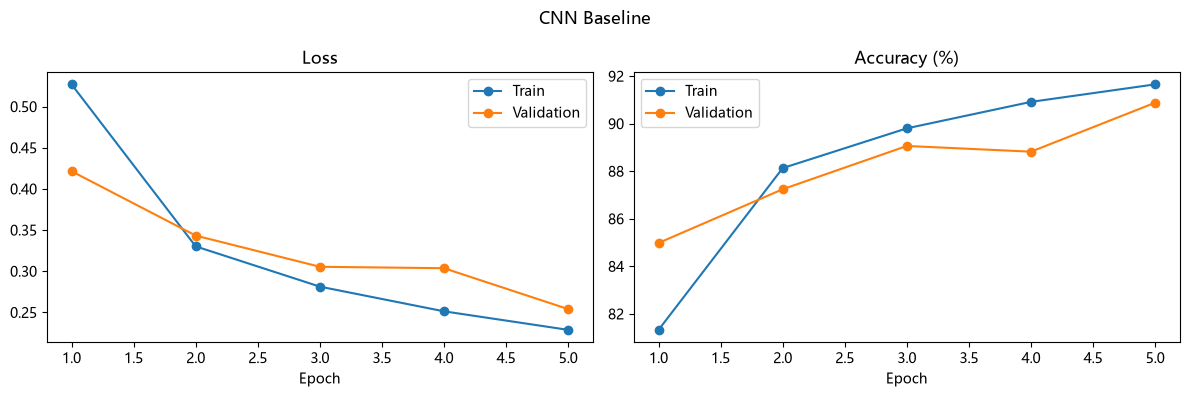

In [4]:
cnn, cnn_history, cnn_metrics = fit_model(
    model=CNN(),
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    run_name="cnn_baseline"
)
display(cnn_history)
print(json.dumps(cnn_metrics, ensure_ascii=False, indent=2))
plot_history(cnn_history, "CNN Baseline")


## 4. 与 MLP 基线比较

如果已经运行过 `01_mlp_baseline.ipynb`，可以读取其验证集指标。请注意：验证指标用于开发阶段比较，不要据此反复查看测试集结果。

In [5]:
mlp_metrics_path = RESULTS_DIR / "mlp_baseline_metrics.json"
if mlp_metrics_path.exists():
    mlp_metrics = json.loads(mlp_metrics_path.read_text(encoding="utf-8"))
    comparison = pd.DataFrame([
        {
            "model": "MLP",
            "final_val_accuracy_pct": mlp_metrics["final_val_accuracy_pct"],
            "best_val_accuracy_pct": mlp_metrics["best_val_accuracy_pct"],
            "final_val_loss": mlp_metrics["final_val_loss"],
        },
        {
            "model": "CNN",
            "final_val_accuracy_pct": cnn_metrics["final_val_accuracy_pct"],
            "best_val_accuracy_pct": cnn_metrics["best_val_accuracy_pct"],
            "final_val_loss": cnn_metrics["final_val_loss"],
        },
    ])
    display(comparison)
    comparison.to_csv(RESULTS_DIR / "mlp_cnn_validation_comparison.csv", index=False)
else:
    print("未找到 MLP 指标。请先运行 01_mlp_baseline.ipynb，再执行本单元格。")


,model,final_val_accuracy_pct,best_val_accuracy_pct,final_val_loss
0,MLP,86.26,87.12,0.367969
1,CNN,90.88,90.88,0.253943


## 5. 验证集错误案例分析

这一环节只查看**验证集**，不查看测试集。请找出至少 5 个错误预测，记录真实类别、预测类别和你观察到的现象。对原因的解释应标注为推测，不要把视觉印象直接当成已证实的机制。

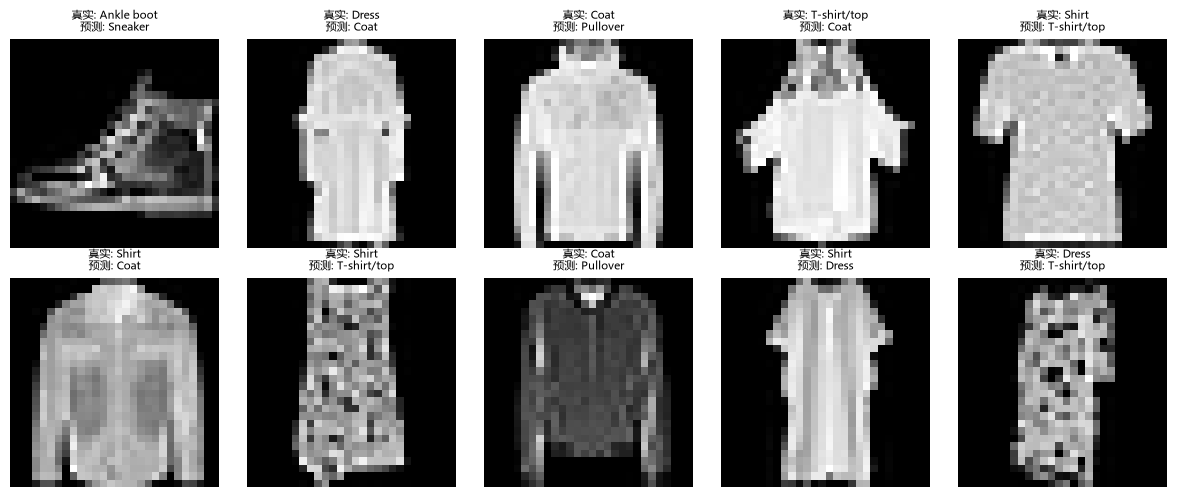

已展示并保存 10 个验证集错误案例。


In [6]:
cnn.eval()
wrong_cases = []
with torch.no_grad():
    for images, labels in val_loader:
        logits = cnn(images.to(device))
        preds = logits.argmax(dim=1).cpu()
        wrong_mask = preds != labels
        for idx in wrong_mask.nonzero(as_tuple=True)[0].tolist():
            wrong_cases.append((images[idx].cpu(), int(labels[idx]), int(preds[idx])))
            if len(wrong_cases) >= 10:
                break
        if len(wrong_cases) >= 10:
            break

if not wrong_cases:
    print("当前模型未发现错误预测；请确认验证流程正常。")
else:
    fig, axes = plt.subplots(2, 5, figsize=(12, 5))
    for ax in axes.flat:
        ax.axis("off")
    for ax, (image, true_label, pred_label) in zip(axes.flat, wrong_cases):
        ax.imshow(image.squeeze(0), cmap="gray")
        ax.set_title(
            f"真实: {class_names[true_label]}\n预测: {class_names[pred_label]}",
            fontsize=8
        )
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "cnn_validation_error_cases.png", dpi=150)
    plt.show()
    print(f"已展示并保存 {len(wrong_cases)} 个验证集错误案例。")


## 6. 结构变体：卷积通道从 32/64 改成 16/32

基线权重和指标保留不动，变体另存为 `cnn_structure_variant`。卷积核还是 3，其它训练设置和基线一致，只改通道数这一个结构参数。

[cnn_structure_variant] Epoch 01/5 | train loss=0.5951, train acc=79.01% | val loss=0.4193, val acc=84.84%


[cnn_structure_variant] Epoch 02/5 | train loss=0.3695, train acc=86.88% | val loss=0.3569, val acc=87.16%


[cnn_structure_variant] Epoch 03/5 | train loss=0.3206, train acc=88.49% | val loss=0.3403, val acc=87.66%


[cnn_structure_variant] Epoch 04/5 | train loss=0.2905, train acc=89.63% | val loss=0.3040, val acc=89.14%


[cnn_structure_variant] Epoch 05/5 | train loss=0.2686, train acc=90.24% | val loss=0.2956, val acc=89.16%


,epoch,train_loss,train_accuracy_pct,val_loss,val_accuracy_pct,learning_rate
0,1,0.595107,79.010909,0.419289,84.84,0.001
1,2,0.369457,86.881818,0.356902,87.16,0.001
2,3,0.320634,88.487273,0.340319,87.66,0.001
3,4,0.290531,89.632727,0.303955,89.14,0.001
4,5,0.268646,90.240000,0.295585,89.16,0.001


{
  "run_name": "cnn_structure_variant",
  "seed": 42,
  "epochs": 5,
  "learning_rate": 0.001,
  "final_train_loss": 0.26864620213508605,
  "final_train_accuracy_pct": 90.24,
  "final_val_loss": 0.2955851606965065,
  "final_val_accuracy_pct": 89.16,
  "best_val_accuracy_pct": 89.16,
  "device": "cpu"
}


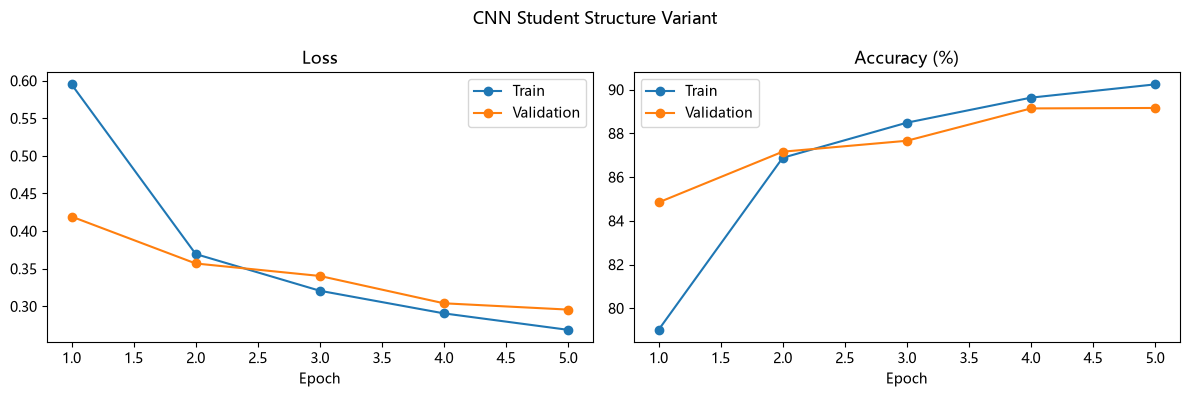

In [7]:
# 学生修改：只改结构变量——卷积通道数 32/64 -> 16/32，卷积核仍为 3，其余训练设置不变
cnn_variant, cnn_variant_history, cnn_variant_metrics = fit_model(
    model=CNN(channels_1=16, channels_2=32, kernel_size=3),
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    run_name="cnn_structure_variant"
)
display(cnn_variant_history)
print(json.dumps(cnn_variant_metrics, ensure_ascii=False, indent=2))
plot_history(cnn_variant_history, "CNN Student Structure Variant")

### 结构修改说明

只改了一个结构参数：两层卷积的输出通道从 `32/64` 减到 `16/32`，卷积核还是 3，分类头输入跟着从 `64×7×7` 变成 `32×7×7`。

这么改是想看看容量少一半会掉多少：参数量从 421,642 降到 206,922（约 49.1%），主要省在分类头那个全连接层。

预期：训练更快、验证准确率比基线低一点；如果差距很小，说明原来 32/64 通道对这个任务有点冗余。

实际跑出来：

- 基线 `cnn_baseline`（32/64）：训练损失 0.2287 / 准确率 91.65%，验证损失 0.2539 / 准确率 90.88%
- 变体 `cnn_structure_variant`（16/32）：训练损失 0.2686 / 准确率 90.24%，验证损失 0.2956 / 准确率 89.16%
- 对比：验证准确率 −1.72 个百分点，验证损失 +0.0416

差距不算大，小模型也能到 89% 左右，但容量减少确实有代价。同样只有一个种子，这个 −1.72 也不能当成精确的“容量效应”。


## 5. 结构修改与错误分析小结

通道减半后参数量从 421,642 降到 206,922，验证准确率 89.16%，比基线低 1.72 个百分点。错误案例全部取自验证集，只记录了真实类别、预测类别、置信度和我的推测，没有拿测试集挑样本。

## 思考题
1. 为什么卷积层的输入有通道维度？
2. `channels_2 * 7 * 7` 是如何得到的？
3. 卷积的局部连接与权重共享意味着什么？
4. 为什么 CNN 的结果不一定在每次运行中都优于 MLP？
5. 为什么比较模型时需要控制数据划分和训练设置？